In [4]:
import sys

import matplotlib
import numpy
import pandas
import sklearn

print(
    sys.version.split()[0],
    numpy.__version__,
    pandas.__version__,
    sklearn.__version__,
    matplotlib.__version__
)

3.12.10 2.3.4 2.3.3 1.7.2 3.10.7


In [5]:
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold, train_test_split

SEED = 3101

data = pd.read_csv("data/spambase.csv")

feature_names = [
    column for column in data.columns
    if column != "spam"
]

X = data[feature_names].to_numpy()
y = data["spam"].to_numpy()

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    stratify=y,
    random_state=SEED
)

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED
)

print(
    X.shape,
    round(100 * y.mean(), 1),
    X_train.shape,
    X_test.shape
)

assert X.shape == (4204, 57)
assert X_train.shape == (3153, 57)
assert X_test.shape == (1051, 57)

(4204, 57) 39.9 (3153, 57) (1051, 57)


# Task 4 — Random Forests & Ensembles

**Student:** Rakhimbek Baizhan  
**SEED:** 3101 — the last four digits of my student ID.

The dataset contains 4,204 emails described by 57 numerical features.
The target is `spam`: 1 represents spam and 0 represents legitimate email.

I use a stratified 75% training and 25% test split. Cross-validation
comparisons use the same five stratified folds of the training split.

All standard deviations use `ddof=0`. A paired difference is inside
the fold spread when its absolute mean is no greater than its standard
deviation. In that case, I do not declare a winner.

Thresholds, the best voting member and the number of boosting rounds
are selected using training data only.

In [6]:
from sklearn.ensemble import (
    AdaBoostClassifier,
    BaggingClassifier,
    RandomForestClassifier
)
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.tree import DecisionTreeClassifier

tree = DecisionTreeClassifier(random_state=SEED)

bag = BaggingClassifier(
    DecisionTreeClassifier(),
    n_estimators=100,
    oob_score=True,
    random_state=SEED
)

rf = RandomForestClassifier(
    n_estimators=300,
    oob_score=True,
    random_state=SEED,
    n_jobs=-1
)

lr = make_pipeline(
    FunctionTransformer(np.log1p),
    StandardScaler(),
    LogisticRegression(max_iter=2000)
)

bag_lr = BaggingClassifier(
    lr,
    n_estimators=50,
    random_state=SEED
)

knn = make_pipeline(
    FunctionTransformer(np.log1p),
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=15)
)

ada = AdaBoostClassifier(
    n_estimators=400,
    random_state=SEED
)

members = [
    ("lr", lr),
    ("knn", knn),
    ("tree", tree)
]

In [7]:
import math
from itertools import combinations

import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.ensemble import VotingClassifier, StackingClassifier
from sklearn.inspection import permutation_importance
from sklearn.model_selection import cross_validate, cross_val_predict
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    confusion_matrix,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve
)

cv_scores = {}


def score_table(score_dict):
    """Build a table of five fold scores, their mean and population std."""
    table = pd.DataFrame.from_dict(
        score_dict,
        orient="index",
        columns=[f"Fold {i}" for i in range(1, 6)]
    )

    table["Mean"] = [
        np.mean(values) for values in score_dict.values()
    ]

    table["Std"] = [
        np.std(values, ddof=0) for values in score_dict.values()
    ]

    return table


def print_table(table):
    """Print numerical results to six decimal places."""
    print(
        table.to_string(
            float_format=lambda value: f"{value:.6f}"
        )
    )


def compare_scores(label, differences):
    """Interpret paired accuracy differences using the handout rule."""
    mean = np.mean(differences)
    std = np.std(differences, ddof=0)

    if abs(mean) <= std:
        conclusion = "Inside the fold spread: no winner."
    elif mean > 0:
        conclusion = "Outside the spread: the first model performs better."
    else:
        conclusion = "Outside the spread: the second model performs better."

    print(
        f"{label}: mean={mean:.6f}, std={std:.6f}. "
        f"{conclusion}"
    )

## Part 1 — Bagging and Out-of-Bag Estimates

In [8]:
def oob_mask(sample_indices, n_samples):
    """Return a boolean mask of rows absent from the bootstrap sample."""
    mask = np.ones(n_samples, dtype=bool)
    indices = np.asarray(sample_indices, dtype=np.intp)
    mask[indices] = False
    return mask

In [9]:
assert np.array_equal(
    oob_mask([0, 2, 2], 5),
    [False, True, False, True, True]
)

assert np.array_equal(
    oob_mask([], 3),
    [True, True, True]
)

indices = np.array([3, 0])
original_indices = indices.copy()

mask_result = oob_mask(
    sample_indices=indices,
    n_samples=4
)

assert np.array_equal(mask_result, [False, True, True, False])
assert np.array_equal(indices, original_indices)
assert mask_result.dtype == np.bool_
assert mask_result.shape == (4,)

print("All oob_mask checks passed.")

bag.fit(X_train, y_train)

n = len(y_train)
oob_shares = []
votes = np.zeros((n, 2), dtype=int)

for estimator, sample_indices, features in zip(
    bag.estimators_,
    bag.estimators_samples_,
    bag.estimators_features_
):
    mask = oob_mask(sample_indices, n)
    oob_shares.append(mask.mean())

    rows = np.flatnonzero(mask)

    predictions = estimator.predict(
        X_train[mask][:, features]
    ).astype(int)

    votes[rows, predictions] += 1

mean_oob_share = np.mean(oob_shares)
expected_oob_share = (1 - 1 / n) ** n

share_table = pd.DataFrame(
    {
        "Measured mean": [
            mean_oob_share,
            1 - mean_oob_share
        ],
        "Theoretical value": [
            expected_oob_share,
            1 - expected_oob_share
        ]
    },
    index=["Out of bag", "In bag"]
)

print("\nBootstrap row shares:")
print_table(share_table)

assert np.all(votes.sum(axis=1) > 0)

manual_oob_predictions = votes.argmax(axis=1)
manual_oob_accuracy = np.mean(
    manual_oob_predictions == y_train
)

print(f"\nManual OOB accuracy: {manual_oob_accuracy:.12f}")
print(f"Scikit-learn OOB accuracy: {bag.oob_score_:.12f}")

assert manual_oob_accuracy == bag.oob_score_

All oob_mask checks passed.

Bootstrap row shares:
            Measured mean  Theoretical value
Out of bag       0.367913           0.367821
In bag           0.632087           0.632179

Manual OOB accuracy: 0.934031081510
Scikit-learn OOB accuracy: 0.934031081510


In [10]:
part1_models = {
    "tree": tree,
    "bag": bag,
    "rf": rf,
    "lr": lr,
    "bag_lr": bag_lr
}

for name, model in part1_models.items():
    cv_scores[name] = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring="accuracy"
    )["test_score"]

print("Accuracy on the same five training folds:")
print_table(
    score_table({
        name: cv_scores[name]
        for name in part1_models
    })
)

part1_differences = {
    "bag - tree": cv_scores["bag"] - cv_scores["tree"],
    "rf - tree": cv_scores["rf"] - cv_scores["tree"],
    "bag_lr - lr": cv_scores["bag_lr"] - cv_scores["lr"]
}

print("\nPaired fold differences:")
print_table(score_table(part1_differences))

print()
for label, differences in part1_differences.items():
    compare_scores(label, differences)

Accuracy on the same five training folds:
         Fold 1   Fold 2   Fold 3   Fold 4   Fold 5     Mean      Std
tree   0.890650 0.890650 0.898574 0.906349 0.892063 0.895657 0.006097
bag    0.919176 0.933439 0.925515 0.936508 0.936508 0.930229 0.006834
rf     0.938193 0.938193 0.947702 0.949206 0.944444 0.943548 0.004635
lr     0.930269 0.931854 0.928685 0.950794 0.938095 0.935939 0.008084
bag_lr 0.928685 0.930269 0.930269 0.952381 0.938095 0.935940 0.008853

Paired fold differences:
               Fold 1    Fold 2   Fold 3   Fold 4   Fold 5     Mean      Std
bag - tree   0.028526  0.042789 0.026941 0.030159 0.044444 0.034572 0.007473
rf - tree    0.047544  0.047544 0.049128 0.042857 0.052381 0.047891 0.003075
bag_lr - lr -0.001585 -0.001585 0.001585 0.001587 0.000000 0.000001 0.001418

bag - tree: mean=0.034572, std=0.007473. Outside the spread: the first model performs better.
rf - tree: mean=0.047891, std=0.003075. Outside the spread: the first model performs better.
bag_lr - lr: mea

In [11]:
rf.fit(X_train, y_train)

forest_oob = rf.oob_score_
forest_cv_mean = np.mean(cv_scores["rf"])
forest_cv_std = np.std(cv_scores["rf"], ddof=0)

forest_test_accuracy = rf.score(X_test, y_test)

forest_test_se = np.sqrt(
    forest_test_accuracy
    * (1 - forest_test_accuracy)
    / len(y_test)
)

forest_table = pd.DataFrame(
    {
        "Value": [
            forest_oob,
            forest_cv_mean,
            forest_cv_std,
            forest_test_accuracy,
            forest_test_se
        ]
    },
    index=[
        "OOB accuracy",
        "CV mean accuracy",
        "CV standard deviation",
        "Test accuracy",
        "Test standard error"
    ]
)

print_table(forest_table)

oob_cv_difference = abs(forest_oob - forest_cv_mean)

print(f"\nAbsolute OOB-CV difference: {oob_cv_difference:.6f}")
print(f"Forest CV standard deviation: {forest_cv_std:.6f}")
print(f"OOB and CV agree: {oob_cv_difference <= forest_cv_std}")

for name, estimate in [
    ("OOB", forest_oob),
    ("CV mean", forest_cv_mean)
]:
    difference = abs(estimate - forest_test_accuracy)

    print(
        f"{name}: absolute difference from test={difference:.6f}; "
        f"within one test SE={difference <= forest_test_se}"
    )

                         Value
OOB accuracy          0.947352
CV mean accuracy      0.943548
CV standard deviation 0.004635
Test accuracy         0.942912
Test standard error   0.007157

Absolute OOB-CV difference: 0.003804
Forest CV standard deviation: 0.004635
OOB and CV agree: True
OOB: absolute difference from test=0.004440; within one test SE=True
CV mean: absolute difference from test=0.000636; within one test SE=True


### Discussion

The measured mean OOB share is approximately 0.367913, close to the
theoretical value of 0.367821. The small difference is expected because
the measured mean comes from 100 random bootstrap samples. The in-bag
share counts distinct rows seen at least once, not the total number
of bootstrap draws.

My manual OOB accuracy is 0.934031081510, exactly equal to
`bag.oob_score_`. Each row receives votes only from trees that did not
use it for training, and a tied vote selects class 0.

Bagging improves the decision tree's mean CV accuracy from 0.895657
to 0.930229. The paired improvement is 0.034572 with a standard deviation
of 0.007473, so it is outside the fold spread. A fully grown tree has
high variance, and combining bootstrap-trained trees reduces this
variability.

For logistic regression, the paired mean difference is approximately
0.000001 with a standard deviation of 0.001418. This is inside the fold
spread, so there is no winner. Regularized logistic regression is more
stable than a fully grown tree, leaving less variance for bagging to
reduce.

The random forest improves over the tree by 0.047891 on average, with
a paired standard deviation of 0.003075. Random feature subsets help
reduce correlation between trees, in addition to the benefit of averaging.

Forest OOB accuracy is 0.947352, while CV accuracy is 0.943548 with a
standard deviation of 0.004635. Their absolute difference, 0.003804,
is smaller than the CV standard deviation. Therefore, OOB is a fair
stand-in for CV here under the assignment's rule.

Test accuracy is 0.942912 with a standard error of 0.007157. OOB and CV
are both slightly higher, but both differences are within one test
standard error. This comparison is descriptive: test SE does not
represent all uncertainty in OOB and CV.

## Part 2 — Evaluating the Spam Filter

I compare the decision tree and random forest using ROC and
precision-recall curves.

The operating threshold is selected using only out-of-fold probabilities
from the training split. Among thresholds with FPR at most 0.01, I choose
the one with the highest recall. If recall is tied, I select the largest
threshold.

The selected threshold is then applied to the test split without
adjustment.

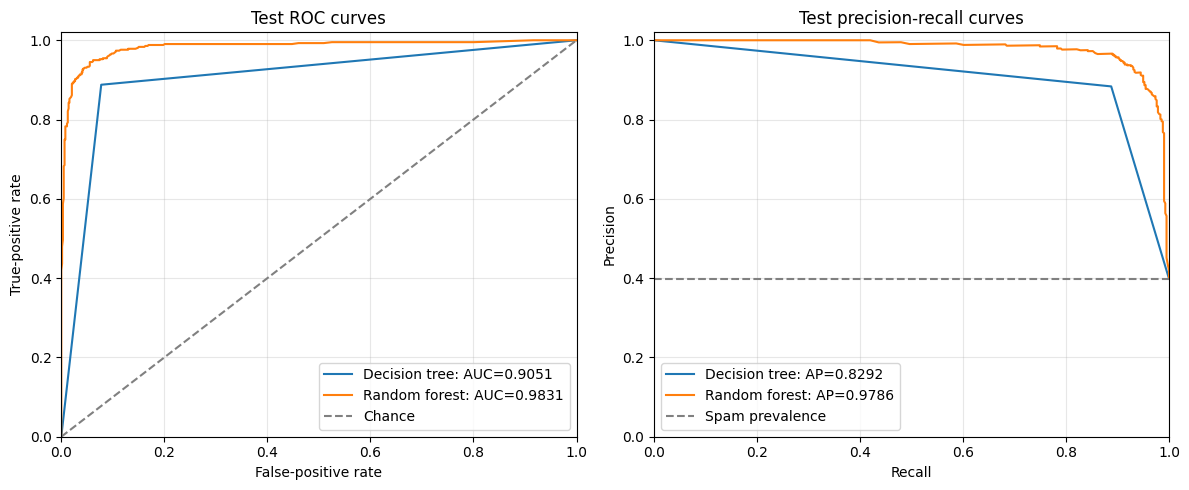

               ROC AUC  Average precision
Model                                    
Decision tree 0.905148           0.829214
Random forest 0.983131           0.978599


In [12]:
tree_fitted = clone(tree).fit(X_train, y_train)

tree_probability = tree_fitted.predict_proba(X_test)[:, 1]
forest_probability = rf.predict_proba(X_test)[:, 1]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

curve_rows = []

for name, probabilities in [
    ("Decision tree", tree_probability),
    ("Random forest", forest_probability)
]:
    fpr_curve, tpr_curve, _ = roc_curve(
        y_test,
        probabilities
    )

    precision_curve, recall_curve, _ = precision_recall_curve(
        y_test,
        probabilities
    )

    auc = roc_auc_score(y_test, probabilities)
    ap = average_precision_score(y_test, probabilities)

    curve_rows.append([name, auc, ap])

    axes[0].plot(
        fpr_curve,
        tpr_curve,
        label=f"{name}: AUC={auc:.4f}"
    )

    axes[1].plot(
        recall_curve,
        precision_curve,
        label=f"{name}: AP={ap:.4f}"
    )

axes[0].plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Chance"
)

axes[0].set(
    xlabel="False-positive rate",
    ylabel="True-positive rate",
    title="Test ROC curves"
)

axes[1].axhline(
    y_test.mean(),
    linestyle="--",
    color="gray",
    label="Spam prevalence"
)

axes[1].set(
    xlabel="Recall",
    ylabel="Precision",
    title="Test precision-recall curves"
)

for ax in axes:
    ax.legend()
    ax.grid(alpha=0.3)
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1.02)

plt.tight_layout()
plt.show()

curve_table = pd.DataFrame(
    curve_rows,
    columns=["Model", "ROC AUC", "Average precision"]
).set_index("Model")

print_table(curve_table)

In [13]:
# Select the threshold using training data only.
oof_probability = cross_val_predict(
    rf,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba"
)[:, 1]

fpr_values, recall_values, threshold_values = roc_curve(
    y_train,
    oof_probability,
    drop_intermediate=False
)

valid_indices = np.flatnonzero(fpr_values <= 0.01)

highest_recall = recall_values[valid_indices].max()

tied_indices = valid_indices[
    recall_values[valid_indices] == highest_recall
]

selected_index = tied_indices[
    np.argmax(threshold_values[tied_indices])
]

threshold = float(threshold_values[selected_index])

selected_oof_fpr = fpr_values[selected_index]
selected_oof_recall = recall_values[selected_index]

assert selected_oof_fpr <= 0.01

print("Selected threshold:", repr(threshold))
print(f"OOF FPR: {selected_oof_fpr:.6f}")
print(f"OOF recall: {selected_oof_recall:.6f}")

# Apply the unrounded threshold once to the test split.
test_predictions = (
    forest_probability >= threshold
).astype(int)

cm = confusion_matrix(
    y_test,
    test_predictions,
    labels=[0, 1]
)

tn, fp, fn, tp = cm.ravel()

test_precision = precision_score(
    y_test,
    test_predictions,
    zero_division=0
)

test_recall = recall_score(
    y_test,
    test_predictions,
    zero_division=0
)

test_fpr = fp / (fp + tn)

confusion_table = pd.DataFrame(
    cm,
    index=["Actual legitimate (0)", "Actual spam (1)"],
    columns=["Predicted legitimate (0)", "Predicted spam (1)"]
)

print("\nConfusion matrix:")
print(confusion_table)

print(f"\nTest precision: {test_precision:.6f}")
print(f"Test recall: {test_recall:.6f}")
print(f"Test FPR: {test_fpr:.6f}")

print(
    f"{fp} of {fp + tn} legitimate test emails "
    "were flagged as spam."
)

print(f"The 1% test FPR target held: {test_fpr <= 0.01}")

Selected threshold: 0.73
OOF FPR: 0.009494
OOF recall: 0.821002

Confusion matrix:
                       Predicted legitimate (0)  Predicted spam (1)
Actual legitimate (0)                       623                   9
Actual spam (1)                              72                 347

Test precision: 0.974719
Test recall: 0.828162
Test FPR: 0.014241
9 of 632 legitimate test emails were flagged as spam.
The 1% test FPR target held: False


In [14]:
perm = permutation_importance(
    rf,
    X_test,
    y_test,
    n_repeats=10,
    random_state=SEED,
    scoring="accuracy"
)

importance_table = pd.DataFrame(
    {
        "Impurity importance": rf.feature_importances_,
        "Permutation mean": perm.importances_mean,
        "Permutation std": perm.importances_std
    },
    index=feature_names
)

importance_table["Impurity rank"] = (
    importance_table["Impurity importance"]
    .rank(ascending=False, method="min")
    .astype(int)
)

importance_table["Permutation rank"] = (
    importance_table["Permutation mean"]
    .rank(ascending=False, method="min")
    .astype(int)
)

impurity_top5 = importance_table.sort_values(
    "Impurity importance",
    ascending=False
).head(5)

permutation_top5 = importance_table.sort_values(
    "Permutation mean",
    ascending=False
).head(5)

print("Top five impurity importances:")
print_table(
    impurity_top5[["Impurity importance", "Impurity rank"]]
)

print("\nTop five permutation importances:")
print_table(
    permutation_top5[
        ["Permutation mean", "Permutation std", "Permutation rank"]
    ]
)

print("\nExample of different rankings:")
print_table(
    importance_table.loc[["word_freq_free"]]
)

Top five impurity importances:
                            Impurity importance  Impurity rank
char_freq_exclam                       0.112087              1
char_freq_dollar                       0.095589              2
word_freq_remove                       0.079824              3
word_freq_free                         0.070841              4
capital_run_length_average             0.062614              5

Top five permutation importances:
                            Permutation mean  Permutation std  Permutation rank
word_freq_remove                    0.027593         0.005819                 1
word_freq_hp                        0.016651         0.004568                 2
char_freq_exclam                    0.010371         0.004651                 3
char_freq_dollar                    0.007136         0.003566                 4
capital_run_length_average          0.006565         0.002706                 5

Example of different rankings:
                Impurity importance  Permuta

### Discussion

The selected threshold is 0.73. At this threshold, training OOF FPR
is approximately 0.009494 and recall is 0.821002.

On the test split, precision is 0.974719, recall is 0.828162 and FPR
is 0.014241. Nine of 632 legitimate emails are incorrectly flagged.
Therefore, the 1% false-positive target does not hold on the test split.

I keep the threshold unchanged. Selecting it again after observing test
performance would use the test split for tuning. Meeting the target on
training OOF predictions does not guarantee that it holds on new data.

The feature `word_freq_free` ranks fourth by impurity importance but
eleventh by permutation importance. Impurity importance measures the
feature's contribution to reducing impurity in the training trees.
Permutation importance measures the decrease in test accuracy after
shuffling the feature.

The rankings can differ because these methods measure different things.
Correlated features may substitute for each other, and impurity importance
can favor features with many possible split points. These are plausible
mechanisms, not a proven causal explanation for this particular feature.
The test importances are descriptive and are not used to choose a model
or change the threshold.

## Part 3 — Voting

In [15]:
def hard_vote(predictions, weights=None):
    """Return weighted majority labels, breaking exact ties by smallest label."""
    predictions = np.asarray(predictions)

    n_models, n_samples = predictions.shape

    if weights is None:
        model_weights = np.ones(n_models, dtype=float)
    else:
        model_weights = np.asarray(weights, dtype=float)

    result = np.zeros(n_samples, dtype=int)

    for sample in range(n_samples):
        labels = np.unique(
            np.append(predictions[:, sample], 0)
        )

        counts = np.zeros(len(labels), dtype=float)

        for model in range(n_models):
            label_index = np.searchsorted(
                labels,
                predictions[model, sample]
            )

            counts[label_index] += model_weights[model]

        result[sample] = labels[np.argmax(counts)]

    return result

In [16]:
import numpy as np
assert np.array_equal(
    hard_vote([[0, 1, 1], [0, 1, 0], [1, 1, 0]]),
    [0, 1, 0]
)

assert np.array_equal(
    hard_vote([[0, 1], [1, 0]]),
    [0, 0]
)

assert np.array_equal(
    hard_vote([[0, 1], [1, 0]], weights=[1, 2]),
    [1, 0]
)

assert np.array_equal(
    hard_vote([[2, 0], [2, 1], [0, 1]]),
    [2, 1]
)

assert np.array_equal(
    hard_vote([[2, 8], [5, 9]], weights=[0, 0]),
    [0, 0]
)

# Counts are compared exactly, without a tolerance.
assert hard_vote(
    [[0], [1], [1]],
    weights=[0.3, 0.1, 0.2]
)[0] == 1

# Weights are accumulated in model order.
assert hard_vote(
    [[1], [1], [1], [0]],
    weights=[1e16, 1, 1, 1e16]
)[0] == 0

input_predictions = np.array([[2, 0], [2, 1], [0, 1]])
input_weights = np.array([1.0, 2.0, 3.0])

predictions_before = input_predictions.copy()
weights_before = input_weights.copy()

check_result = hard_vote(
    predictions=input_predictions,
    weights=input_weights
)

assert np.array_equal(input_predictions, predictions_before)
assert np.array_equal(input_weights, weights_before)
assert np.issubdtype(check_result.dtype, np.integer)
assert check_result.shape == (2,)

print("All hard_vote checks passed.")

member_fits = {
    name: clone(model).fit(X_train, y_train)
    for name, model in members
}

member_predictions = np.vstack([
    member_fits[name].predict(X_test)
    for name, _ in members
])

manual_hard_predictions = hard_vote(member_predictions)

hard = VotingClassifier(members, voting="hard")
soft = VotingClassifier(members, voting="soft")

hard_fitted = clone(hard).fit(X_train, y_train)
sklearn_hard_predictions = hard_fitted.predict(X_test)

agreement = np.mean(
    manual_hard_predictions == sklearn_hard_predictions
)

print(f"\nManual/sklearn hard-vote agreement: {agreement:.6f}")

assert agreement == 1.0

disagreement_rows = []

for i, j in combinations(range(len(members)), 2):
    disagreement_rows.append([
        members[i][0],
        members[j][0],
        np.mean(member_predictions[i] != member_predictions[j])
    ])

disagreement_table = pd.DataFrame(
    disagreement_rows,
    columns=["Member A", "Member B", "Disagreement fraction"]
)

print("\nPairwise test disagreement:")
print_table(disagreement_table)

All hard_vote checks passed.

Manual/sklearn hard-vote agreement: 1.000000

Pairwise test disagreement:
  Member A Member B  Disagreement fraction
0       lr      knn               0.040913
1       lr     tree               0.085633
2      knn     tree               0.088487


In [17]:
# lr and tree already have scores from the same folds in Part 1.
for name, model in [
    ("knn", knn),
    ("hard", hard),
    ("soft", soft)
]:
    cv_scores[name] = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring="accuracy"
    )["test_score"]

voting_names = ["lr", "knn", "tree", "hard", "soft"]

print("Members and voting ensembles on the same folds:")
print_table(
    score_table({
        name: cv_scores[name]
        for name in voting_names
    })
)

member_names = [name for name, _ in members]

best_member_name = max(
    member_names,
    key=lambda name: np.mean(cv_scores[name])
)

best_member = dict(members)[best_member_name]

print(f"\nBest member selected by training CV: {best_member_name}")

part3_differences = {
    f"hard - {best_member_name}": (
        cv_scores["hard"] - cv_scores[best_member_name]
    ),
    f"soft - {best_member_name}": (
        cv_scores["soft"] - cv_scores[best_member_name]
    )
}

print("\nPaired fold differences:")
print_table(score_table(part3_differences))

print()
for label, differences in part3_differences.items():
    compare_scores(label, differences)

Members and voting ensembles on the same folds:
       Fold 1   Fold 2   Fold 3   Fold 4   Fold 5     Mean      Std
lr   0.930269 0.931854 0.928685 0.950794 0.938095 0.935939 0.008084
knn  0.919176 0.893819 0.922345 0.928571 0.925397 0.917862 0.012420
tree 0.890650 0.890650 0.898574 0.906349 0.892063 0.895657 0.006097
hard 0.935024 0.925515 0.944532 0.949206 0.936508 0.938157 0.008186
soft 0.930269 0.927100 0.944532 0.946032 0.933333 0.936253 0.007646

Best member selected by training CV: lr

Paired fold differences:
            Fold 1    Fold 2   Fold 3    Fold 4    Fold 5     Mean      Std
hard - lr 0.004754 -0.006339 0.015848 -0.001587 -0.001587 0.002218 0.007673
soft - lr 0.000000 -0.004754 0.015848 -0.004762 -0.004762 0.000314 0.007983

hard - lr: mean=0.002218, std=0.007673. Inside the fold spread: no winner.
soft - lr: mean=0.000314, std=0.007983. Inside the fold spread: no winner.


### Discussion

My hard-voting function agrees with `VotingClassifier(voting="hard")`
on every test row. It supports non-negative multiclass labels, does not
normalize weights, adds them in model order and resolves exact ties
using the smallest label.

The pairwise disagreement fractions are approximately 0.040913 for
logistic regression and KNN, 0.085633 for logistic regression and the
tree, and 0.088487 for KNN and the tree.

Logistic regression is the best individual member by training CV mean.
Hard voting improves over it by 0.002218 on average, with a paired
standard deviation of 0.007673. Soft voting improves by 0.000314,
with a paired standard deviation of 0.007983.

Both differences are inside the fold spread. Therefore, neither hard
nor soft voting is a clear winner over the best member.

Disagreement provides diversity, but diversity alone does not guarantee
better accuracy. Hard voting combines labels, while soft voting averages
the members' predicted probabilities.

## Part 4 — Stacking

I construct a meta-training matrix using the members' out-of-fold spam
probabilities in the order: logistic regression, KNN and decision tree.

Each row's OOF probability is produced by a model that did not train
on that row. The meta-learner is `LogisticRegression()` with default
settings.

I compare this construction with `StackingClassifier` and with a naive
meta-learner trained on in-sample probabilities.

In [18]:
meta_oof_train = np.column_stack([
    cross_val_predict(
        model,
        X_train,
        y_train,
        cv=cv,
        method="predict_proba"
    )[:, 1]
    for _, model in members
])

assert meta_oof_train.shape == (len(y_train), 3)

manual_meta = LogisticRegression().fit(
    meta_oof_train,
    y_train
)

stack_member_fits = [
    clone(model).fit(X_train, y_train)
    for _, model in members
]

meta_test = np.column_stack([
    fitted_model.predict_proba(X_test)[:, 1]
    for fitted_model in stack_member_fits
])

manual_stack_predictions = manual_meta.predict(meta_test)

stack = StackingClassifier(
    members,
    LogisticRegression(),
    cv=cv
).fit(X_train, y_train)

sklearn_stack_predictions = stack.predict(X_test)

coefficient_difference = np.max(
    np.abs(
        manual_meta.coef_
        - stack.final_estimator_.coef_
    )
)

intercept_difference = np.max(
    np.abs(
        manual_meta.intercept_
        - stack.final_estimator_.intercept_
    )
)

manual_stack_accuracy = accuracy_score(
    y_test,
    manual_stack_predictions
)

sklearn_stack_accuracy = stack.score(X_test, y_test)

identical_predictions = np.array_equal(
    manual_stack_predictions,
    sklearn_stack_predictions
)

print(
    "Largest absolute coefficient difference:",
    coefficient_difference
)
print(
    "Largest absolute intercept difference:",
    intercept_difference
)
print("Identical test predictions:", identical_predictions)
print(f"Manual test accuracy: {manual_stack_accuracy:.12f}")
print(f"Sklearn test accuracy: {sklearn_stack_accuracy:.12f}")

assert np.allclose(
    manual_meta.coef_,
    stack.final_estimator_.coef_,
    atol=1e-10,
    rtol=0
)
assert identical_predictions
assert manual_stack_accuracy == sklearn_stack_accuracy

# Naive stacking uses predictions on the same rows used for fitting.
meta_naive_train = np.column_stack([
    clone(model)
    .fit(X_train, y_train)
    .predict_proba(X_train)[:, 1]
    for _, model in members
])

naive_meta = LogisticRegression().fit(
    meta_naive_train,
    y_train
)

coefficient_table = pd.DataFrame(
    {
        "Naive in-sample": naive_meta.coef_[0],
        "Out-of-fold": manual_meta.coef_[0]
    },
    index=[name for name, _ in members]
)

print("\nMeta-learner coefficients:")
print_table(coefficient_table)

print(
    "\nTree in-sample accuracy:",
    accuracy_score(y_train, meta_naive_train[:, 2] >= 0.5)
)

print(
    "Tree OOF accuracy:",
    accuracy_score(y_train, meta_oof_train[:, 2] >= 0.5)
)

Largest absolute coefficient difference: 0.0
Largest absolute intercept difference: 0.0
Identical test predictions: True
Manual test accuracy: 0.940057088487
Sklearn test accuracy: 0.940057088487

Meta-learner coefficients:
      Naive in-sample  Out-of-fold
lr           1.965418     3.750786
knn          1.894383     3.150587
tree         8.267808     1.359943

Tree in-sample accuracy: 1.0
Tree OOF accuracy: 0.8956549318109737


In [19]:
# Each outer training fold gets its own inner stacking CV.
cv_scores["stack"] = cross_validate(
    stack,
    X_train,
    y_train,
    cv=cv,
    scoring="accuracy"
)["test_score"]

print("Stacking, soft voting and the best member:")
print_table(
    score_table({
        "stack": cv_scores["stack"],
        "soft": cv_scores["soft"],
        best_member_name: cv_scores[best_member_name]
    })
)

part4_differences = {
    f"stack - {best_member_name}": (
        cv_scores["stack"] - cv_scores[best_member_name]
    ),
    "stack - soft": (
        cv_scores["stack"] - cv_scores["soft"]
    )
}

print("\nPaired fold differences:")
print_table(score_table(part4_differences))

print()
for label, differences in part4_differences.items():
    compare_scores(label, differences)

Stacking, soft voting and the best member:
        Fold 1   Fold 2   Fold 3   Fold 4   Fold 5     Mean      Std
stack 0.938193 0.927100 0.944532 0.947619 0.946032 0.940695 0.007513
soft  0.930269 0.927100 0.944532 0.946032 0.933333 0.936253 0.007646
lr    0.930269 0.931854 0.928685 0.950794 0.938095 0.935939 0.008084

Paired fold differences:
               Fold 1    Fold 2   Fold 3    Fold 4   Fold 5     Mean      Std
stack - lr   0.007924 -0.004754 0.015848 -0.003175 0.007937 0.004756 0.007701
stack - soft 0.007924  0.000000 0.000000  0.001587 0.012698 0.004442 0.005058

stack - lr: mean=0.004756, std=0.007701. Inside the fold spread: no winner.
stack - soft: mean=0.004442, std=0.005058. Inside the fold spread: no winner.


### Discussion

The manual OOF stack reproduces scikit-learn's meta-learner coefficients
and test predictions. The largest coefficient difference is zero,
and both test accuracies are approximately 0.940057.

The tree's coefficient falls from 8.267808 in naive stacking to 1.359943
in OOF stacking. Its in-sample accuracy is 1.0, while its OOF accuracy
is approximately 0.895655.

A fully grown tree can memorize its training rows. Its in-sample
probabilities therefore make it appear unusually reliable to the naive
meta-learner. OOF probabilities reveal errors on unseen rows and lead
to a much smaller tree coefficient.

These coefficients are logistic-regression coefficients, not normalized
voting weights. They do not need to sum to one.

Stacking improves over logistic regression by 0.004756 on average,
with a paired standard deviation of 0.007701. Its improvement over
soft voting is 0.004442, with a paired standard deviation of 0.005058.

Both differences are inside the fold spread, so stacking is not a clear
winner over either comparator. The stacking CV is nested: each outer
training fold constructs its own inner OOF predictions.